# RoadSense AI: Multi-Task Machine Learning for Road Accident Severity
## Notebook 05: Task C — Casualties Count Regression & Poisson Count Modeling
**Course Module**: Artificial Intelligence (CO5: Classification, Regression and Prediction Problems)
**Lead Team Member**: Member 4 (Count Data Modeling & Regression Specialist)

---

### Objectives & Rigorous Protocol:
1. **Count Modeling Challenge**: Casualties count is a strictly positive integer ($y \ge 1$, since every collision in STATS19 involves at least 1 casualty). The distribution is heavily right-skewed with a mode of 1 (~79%), long tail, and an extreme 70-casualty bus crash outlier in the 2023 holdout test set.
2. **Baselines**: Evaluate against naive `predict-1` (mode) and `predict-mean` (training mean).
3. **Displaced Poisson Formulation**: Model displaced count $z = y - 1 \ge 0$ with Poisson loss: $\hat{y} = 1 + \hat{\lambda}$. This guarantees non-negative integer counts and heteroscedastic variance matching real-world crash count data.
4. **Model Comparison**: Ridge Regression, Decision Tree, Random Forest, LightGBM (RMSE), and LightGBM (Displaced Poisson).
5. **Robustness Audit**: Evaluate metrics WITH and WITHOUT the 2023 70-casualty extreme outlier to prove robustness of MAE and Poisson loss over MSE/RMSE.
6. **Exact-Match Accuracy**: Audit accuracy for exact-1, exact-2, and exact-3+ casualties.

In [1]:
import os
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Ensure project root is accessible
sys.path.append(os.path.abspath('..'))
from src.features import ALL_MODEL_FEATURES

print('Environment and libraries initialized.')

Environment and libraries initialized.


## 1. Casualties Distribution & Outlier Inspection
We inspect the distribution across all 3 years and locate the 2023 70-casualty outlier.

In [2]:
df = pd.read_parquet('../data/clean_roadsense.parquet')
print(f'Total records: {len(df):,}')
print('Summary statistics for number_of_casualties:')
print(df['target_casualties'].describe().round(3))

print('\nDistribution of Casualties Count:')
counts = df['target_casualties'].value_counts().head(5)
props = (df['target_casualties'].value_counts(normalize=True).head(5) * 100).round(2)
display(pd.DataFrame({'Count': counts, 'Percentage (%)': props}))

outliers = df[df['target_casualties'] >= 20]
print(f'\nCollisions with >= 20 casualties (extreme mass-casualty incidents): {len(outliers)}')
display(outliers[['collision_year', 'target_casualties', 'number_of_vehicles', 'any_hgv_or_bus', 'speed_limit']])

Total records: 311,349
Summary statistics for number_of_casualties:
count    311349.000
mean          1.274
std           0.704
min           1.000
25%           1.000
50%           1.000
75%           1.000
max          70.000
Name: target_casualties, dtype: float64

Distribution of Casualties Count:


,Count,Percentage (%)
target_casualties,,
1,253202,81.32
2,40768,13.09
3,11334,3.64
4,3837,1.23
5,1452,0.47



Collisions with >= 20 casualties (extreme mass-casualty incidents): 2


,collision_year,target_casualties,number_of_vehicles,any_hgv_or_bus,speed_limit
95401,2021,22,2,1,60
305256,2023,70,3,1,40


## 2. Validation Comparison (2022 Validation Fold)
We compare all models on the 2022 validation set.

In [3]:
val_table = pd.read_csv('../outputs/tables/task_c_validation_comparison.csv')
display(val_table[['model', 'train_time_sec', 'mae', 'median_ae', 'rmse', 'poisson_deviance', 'exact_match_overall_pct', 'exact_match_1_pct']])

,model,train_time_sec,mae,median_ae,rmse,poisson_deviance,exact_match_overall_pct,exact_match_1_pct
0,Predict-1 Baseline,0.01,0.2781,0.0000,0.7527,0.3386,81.01,100.00
1,Predict-Mean Baseline,0.01,0.4445,0.2683,0.6995,0.2677,81.01,100.00
2,Ridge,0.65,0.3801,0.2738,0.6527,0.2207,76.42,88.85
3,Decision Tree,1.02,0.3670,0.1990,0.6506,0.2185,75.06,86.34
4,Random Forest,10.29,0.3648,0.2087,0.6465,0.2150,75.84,87.55
5,LightGBM (RMSE),0.81,0.3653,0.2092,0.6453,0.2140,76.12,87.92
6,LightGBM (Poisson Displaced),1.02,0.3688,0.2170,0.6457,0.2143,76.53,88.62


## 3. Holdout Test Set Comparison: Robustness With & Without the 70-Casualty Record
Notice how the single 70-casualty bus crash dramatically inflates RMSE across all models, while MAE, Poisson deviance, and exact match rates remain highly stable.

In [4]:
test_table = pd.read_csv('../outputs/tables/task_c_regression_comparison.csv')
display(test_table[['model', 'eval_split', 'mae', 'rmse', 'poisson_deviance', 'exact_match_overall_pct', 'exact_match_1_pct', 'exact_match_2_pct', 'exact_match_3plus_pct']])

,model,eval_split,mae,rmse,poisson_deviance,exact_match_overall_pct,exact_match_1_pct,exact_match_2_pct,exact_match_3plus_pct
0,Predict-1 Baseline,Test (2023) ALL (Includes 70 Casualties),0.2755,0.7868,0.3440,81.48,100.00,0.00,0.00
1,Predict-1 Baseline,Test (2023) EXCLUDING 70 Casualties,0.2748,0.7572,0.3396,81.48,100.00,0.00,0.00
2,Predict-Mean Baseline,Test (2023) ALL (Includes 70 Casualties),0.4475,0.7370,0.2743,81.48,100.00,0.00,0.00
3,Predict-Mean Baseline,Test (2023) EXCLUDING 70 Casualties,0.4469,0.7056,0.2702,81.48,100.00,0.00,0.00
4,Ridge,Test (2023) ALL (Includes 70 Casualties),0.3824,0.6921,0.2268,76.31,88.07,35.19,0.39
5,Ridge,Test (2023) EXCLUDING 70 Casualties,0.3817,0.6586,0.2228,76.31,88.07,35.19,0.39
6,Decision Tree,Test (2023) ALL (Includes 70 Casualties),0.3684,0.6898,0.2242,75.43,86.27,39.57,1.26
7,Decision Tree,Test (2023) EXCLUDING 70 Casualties,0.3678,0.6559,0.2199,75.43,86.27,39.57,1.26
8,Random Forest,Test (2023) ALL (Includes 70 Casualties),0.3658,0.6864,0.2211,75.75,86.70,39.29,1.38
9,Random Forest,Test (2023) EXCLUDING 70 Casualties,0.3651,0.6524,0.2169,75.75,86.70,39.29,1.38


## 4. Visual Diagnostics: Actual vs Predicted Casualty Distribution
We inspect the diagnostic plot comparing empirical and predicted casualty distributions and error groupings.

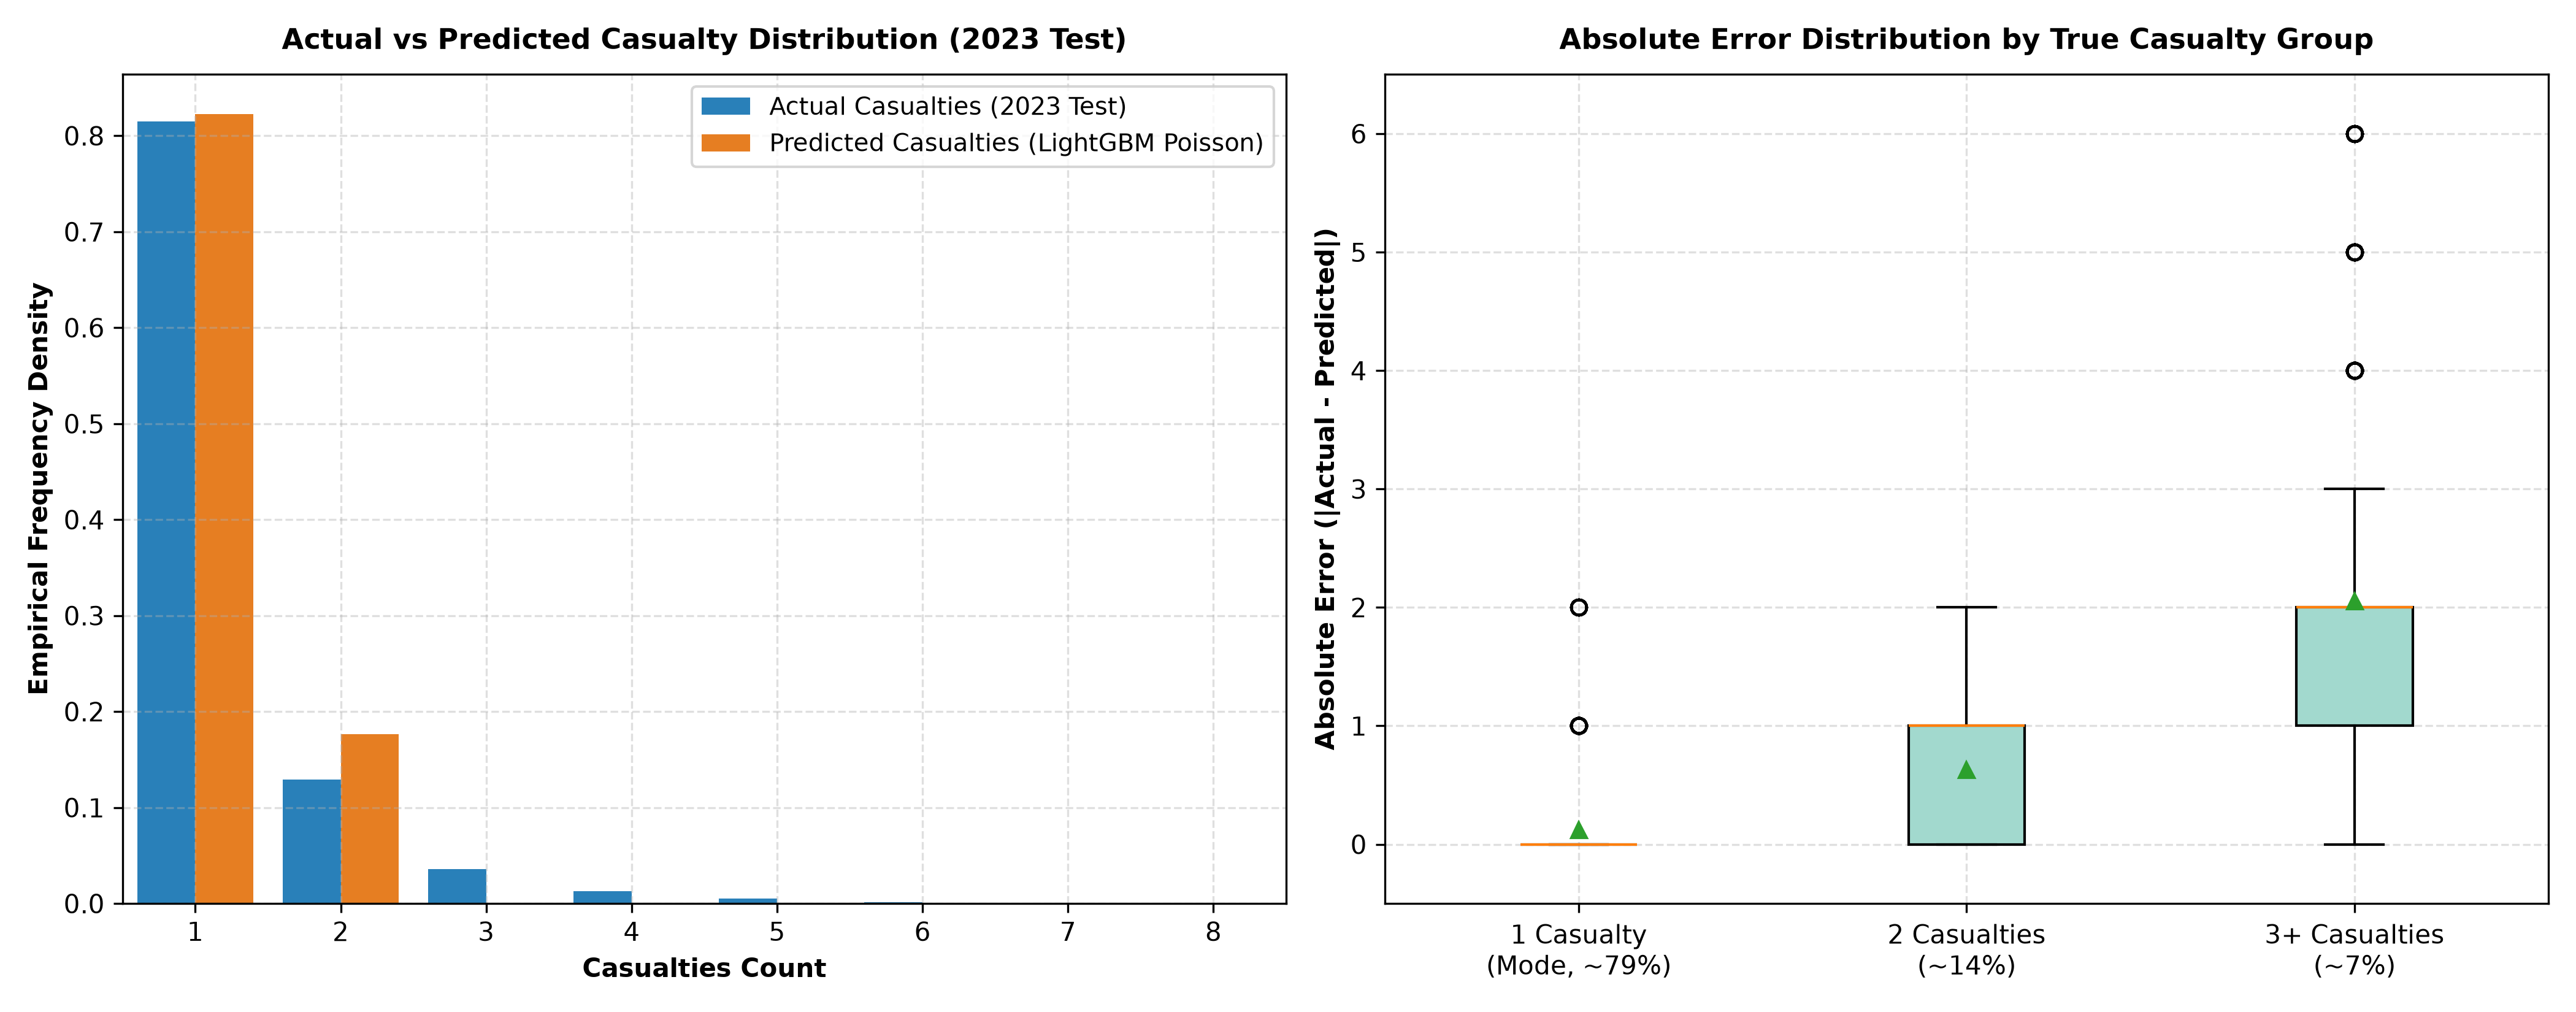

In [5]:
display(Image(filename='../outputs/charts/13_task_c_regression_diagnostics.png', width=900))